## Credit Risk Analytics & Loan Default Prediction

### Phase 6 — Python EDA
### Phase 7 — Statistical Analysis
### Phase 8 — Hypothesis Testing
### Phase 9 — Feature Engineering

#### Objective

Analyze the cleaned credit-risk dataset to identify important patterns, relationships, statistical signals, and risk characteristics, and then transform the available variables into meaningful features suitable for machine-learning models.

#### Business Goal

Understand the factors associated with loan default and prepare a reliable analytical dataset for predictive modeling.

#### Important Principle

Exploratory analysis identifies patterns and generates hypotheses.

Statistical analysis and hypothesis testing will be used to determine whether observed relationships are statistically meaningful.

Feature engineering will transform relevant raw variables into model-ready features.

Observed relationships will not automatically be interpreted as causal relationships.

### 6.1 Load Cleaned Dataset

The cleaned dataset generated during Phase 4 will be loaded for exploratory data analysis.

The dataset has already undergone data-quality treatment, including handling of missing values, anomalous DTI values, and removal of the high-missingness `desc` column.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/LC_loans_granting_model_dataset_cleaned.csv")

print('Dataset loaded successfully')
print("Shape: ",df.shape)

Dataset loaded successfully
Shape:  (1347681, 14)


### 6.2 EDA Objectives and Business Questions

#### Objective

Explore the cleaned credit-risk dataset to identify meaningful patterns, distributions, relationships, and potential risk signals before statistical analysis and feature engineering.

#### Business Questions

1. What is the overall distribution of loan defaults?
2. How are the major numerical borrower and loan variables distributed?
3. How are important categorical borrower and loan characteristics distributed?
4. Does default behavior differ across important borrower and loan segments?
5. How do numerical variables differ between defaulted and non-defaulted loans?
6. Which variables appear to be associated with loan default?
7. Are there strong correlations or potentially redundant numerical features?
8. What key findings should guide statistical analysis and feature engineering?

#### Analytical Principle

EDA is used to discover patterns and generate hypotheses.

Observed relationships will be treated as associations rather than causal relationships.

Formal statistical analysis and hypothesis testing will be performed in later sections of this notebook.

### 6.3 Target Distribution

#### Business Question

What is the distribution of defaulted and non-defaulted loans in the portfolio?

#### Purpose

Understand the baseline distribution of the target variable and identify the degree of class imbalance.

#### Business Importance

The default rate represents the observed baseline credit risk in the portfolio.

Understanding the target distribution is also important for later machine-learning model evaluation because an imbalanced target can make accuracy alone an unreliable performance measure.

In [4]:
# Count loans by default status

default_counts = df['Default'].value_counts().sort_index()

print("Default Distribution")
print(default_counts)

print("\nDefault Distribution (%)")
print((default_counts / len(df) * 100).round(2) )

Default Distribution
Default
0    1078432
1     269249
Name: count, dtype: int64

Default Distribution (%)
Default
0    80.02
1    19.98
Name: count, dtype: float64


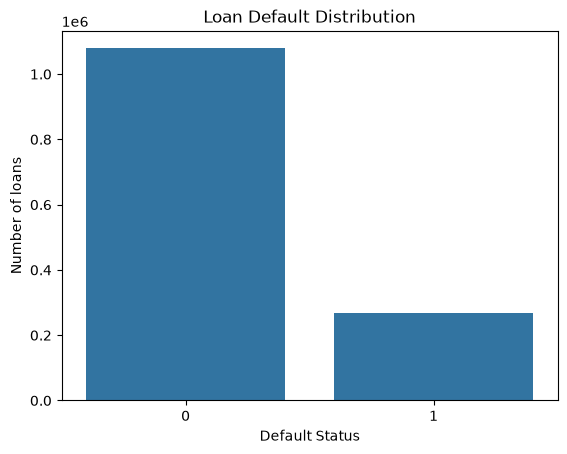

In [5]:
plt.Figure(figsize=(7,5))

sns.countplot(
    data=df,
    x='Default'
)

plt.title('Loan Default Distribution')
plt.xlabel("Default Status")
plt.ylabel("Number of loans")

plt.show()

### 6.4 Numerical Feature Analysis

#### Business Question

What are the distributions and characteristics of the major numerical borrower and loan variables?

#### Numerical Variables

- `revenue`
- `dti_n`
- `loan_amnt`
- `fico_n`
- `experience_c`

#### Purpose

Understand the central tendency, spread, range, and potential extreme values of important numerical variables before examining their relationship with loan default.

#### Business Importance

Understanding the underlying distribution of borrower and loan characteristics provides context for identifying risk patterns and selecting appropriate transformations or features during feature engineering.

In [6]:
numerical_features = [
    "revenue",
    "dti_n",
    "loan_amnt",
    "fico_n",
    "experience_c"
]

numerical_summary = df[numerical_features].describe().T

numerical_summary

,count,mean,std,min,25%,50%,75%,max
revenue,1347681.0,77369.683174,70362.989597,1896.0,46600.00,65000.00,92000.00,10999200.00
dti_n,1347643.0,18.271438,9.861714,0.0,11.82,17.63,24.07,991.57
loan_amnt,1347681.0,14408.230490,8715.347372,500.0,7975.00,12000.00,20000.00,40000.00
fico_n,1347681.0,698.158922,31.848725,612.0,672.00,692.00,712.00,847.50
experience_c,1347681.0,0.999981,0.004307,0.0,1.00,1.00,1.00,1.00


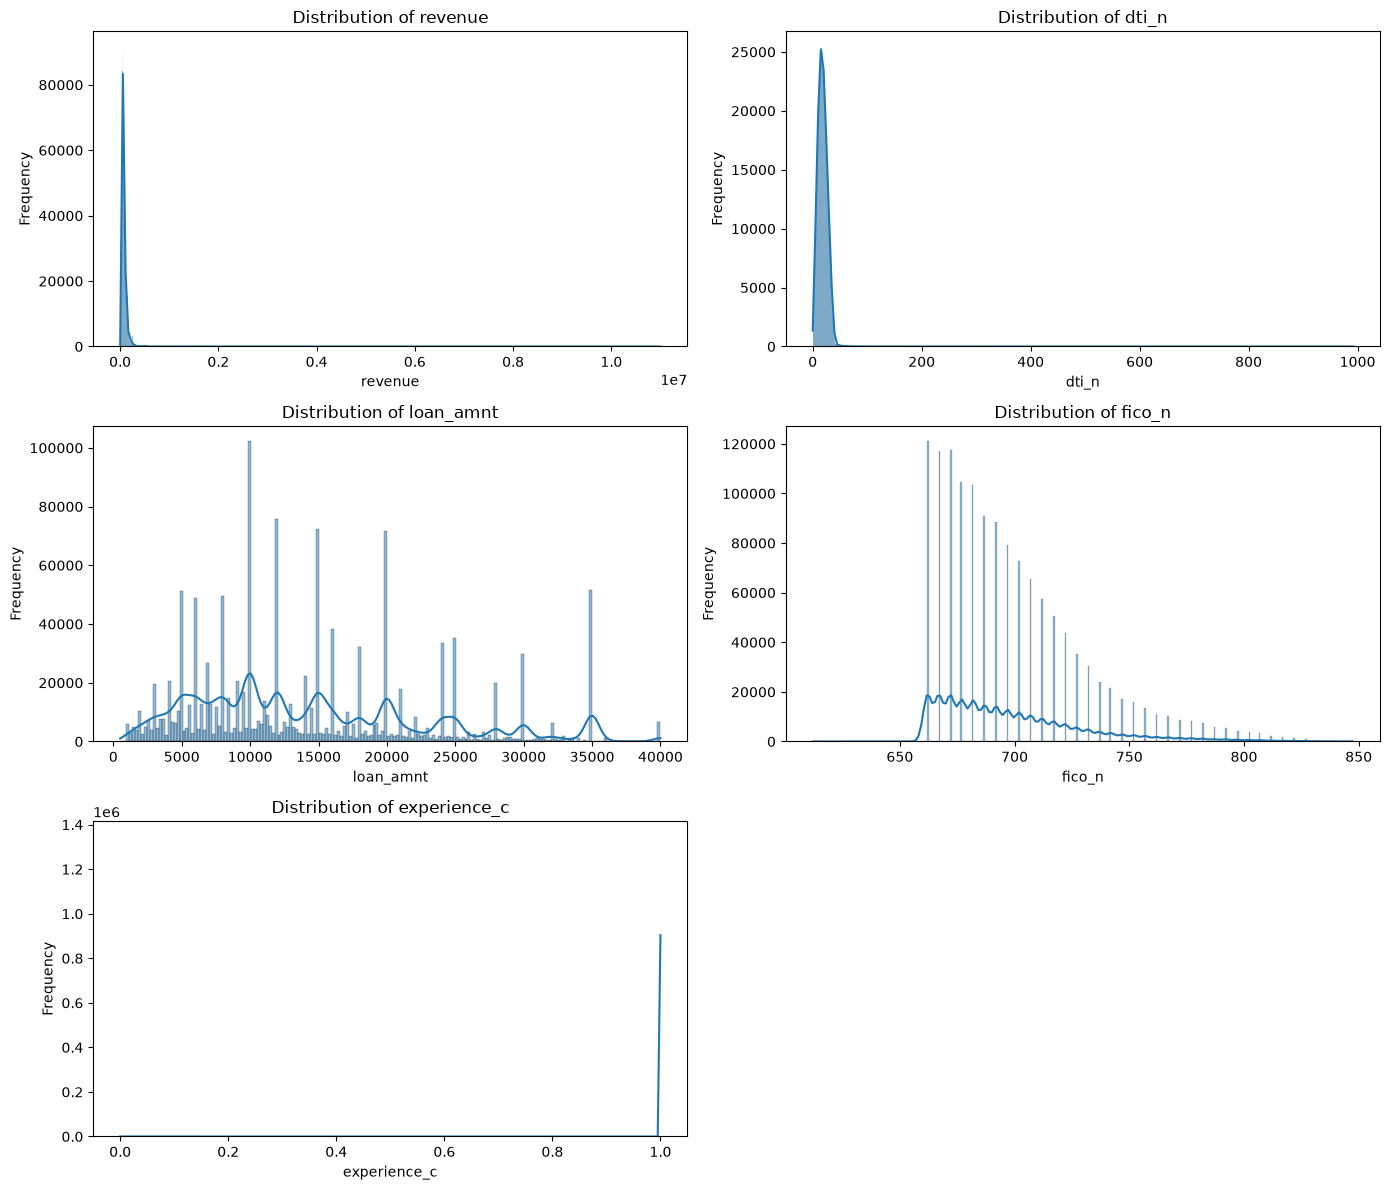

In [7]:
fig, axes = plt.subplots(3,2, figsize=(14,12))

for ax, feature in zip(axes.flatten(),numerical_features):
    sns.histplot(
        data=df,
        x=feature,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")

# Hide the unused sixth subplot
axes.flatten()[-1].set_visible(False)

plt.tight_layout()
plt.show()

#### Numerical EDA Findings

- `revenue` is strongly right-skewed, with most observations concentrated at lower values and a small number of very high-revenue observations.
- `dti_n` is strongly right-skewed and contains a long upper tail. The 38 anomalous `dti_n = 999` values were already handled during Phase 4.
- `loan_amnt` shows a discrete distribution with strong concentrations at commonly issued loan amounts and moderate right skew.
- `fico_n` is relatively concentrated, with most observations falling around the mid-to-high 600s and low 700s.
- `experience_c` is a binary feature with almost all observations equal to 1, indicating very low variation.

These observations describe the structure of the data but do not establish causal relationships with loan default. Relationships with the target variable will be examined in subsequent EDA sections.

### 6.5 Categorical Feature Analysis

#### Business Question

How is the loan portfolio distributed across important borrower, employment, ownership, and loan-purpose categories?

#### Categorical Variables

- `purpose`
- `emp_length`
- `home_ownership_n`
- `addr_state`

#### Purpose

Understand the composition of the loan portfolio and identify categories that may require further investigation for differences in default behavior.

#### Business Importance

Different borrower and loan categories may represent different levels of credit exposure and risk. Understanding their distribution provides context for later default-rate comparisons and risk segmentation.

In [8]:
purpose_count = df['purpose'].value_counts()

print('Loan Purpose Distribution')
print(purpose_count)

Loan Purpose Distribution
purpose
debt_consolidation    781206
credit_card           295551
home_improvement       87684
other                  78263
major_purchase         29543
medical                15606
small_business         15575
car                    14647
moving                  9520
vacation                9083
house                   7294
wedding                 2350
renewable_energy         936
educational              423
Name: count, dtype: int64


In [9]:
# defaulter in purpose

# Default counts and rates by loan purpose
purpose_def_count = (
    df.groupby('purpose')['Default']
      .agg(default_count='sum', loan_count='count', default_rate='mean')
      .sort_values('default_rate', ascending=False)
)

purpose_def_count

,default_count,loan_count,default_rate
purpose,,,
small_business,4650,15575,0.298555
renewable_energy,222,936,0.237179
moving,2229,9520,0.234139
house,1598,7294,0.219084
medical,3409,15606,0.218442
debt_consolidation,165258,781206,0.211542
other,16501,78263,0.210840
educational,88,423,0.208038
vacation,1743,9083,0.191897


### Loan Purpose Default Rate — Interpretation

- Debt consolidation is the largest loan-purpose category and represents a substantial share of the overall portfolio.
- Small business loans show the highest observed default rate at approximately 29.86%.
- Renewable energy and moving loans also show default rates above the overall portfolio default rate of 19.98%.
- Wedding and car loans show comparatively lower observed default rates.
- Default rate should be interpreted together with loan volume because categories with very small sample sizes may produce unstable estimates.
- These results indicate an association between loan purpose and observed default behavior, but they do not establish causation.

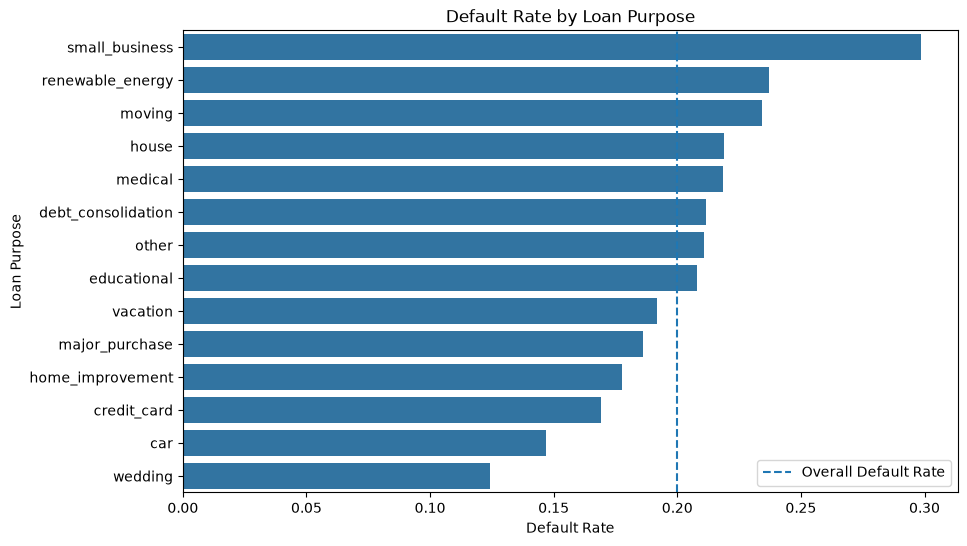

In [10]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=purpose_def_count,
    x='default_rate',
    y='purpose'
)

plt.axvline(
    df['Default'].mean(),
    linestyle='--',
    label='Overall Default Rate'
)

plt.title("Default Rate by Loan Purpose")
plt.xlabel("Default Rate")
plt.ylabel("Loan Purpose")
plt.legend()

plt.show()

### Loan Purpose — EDA Conclusion

Loan purpose shows meaningful variation in observed default rates across categories. Small business loans have the highest observed default rate at approximately 29.86%, while wedding loans have the lowest at approximately 12.43%.

Several categories, including small business, renewable energy, moving, house, and medical, have default rates above the overall portfolio default rate of approximately 19.98%.

However, default rates should be evaluated together with loan volume because smaller categories may have less stable estimates. These findings indicate an association between loan purpose and default behavior but do not establish causation.

### 6.5.2 Employment Length Analysis

#### Business Question

Does borrower employment length have an association with observed loan default behavior?

#### Purpose

Understand how loans are distributed across different employment-length categories and identify categories that may require further credit-risk investigation.

#### Business Importance

Employment history can provide context about a borrower's financial stability. Analyzing employment-length categories may help identify differences in portfolio composition and observed default behavior.

In [11]:
employment_count = df['emp_length'].value_counts().sort_index()

print('Employment Length Distribution')
print(employment_count)

Employment Length Distribution
emp_length
1 year        88841
10+ years    442667
2 years      122091
3 years      107862
4 years       80761
5 years       84326
6 years       62877
7 years       59724
8 years       60808
9 years       51019
< 1 year     108517
NI            78188
Name: count, dtype: int64


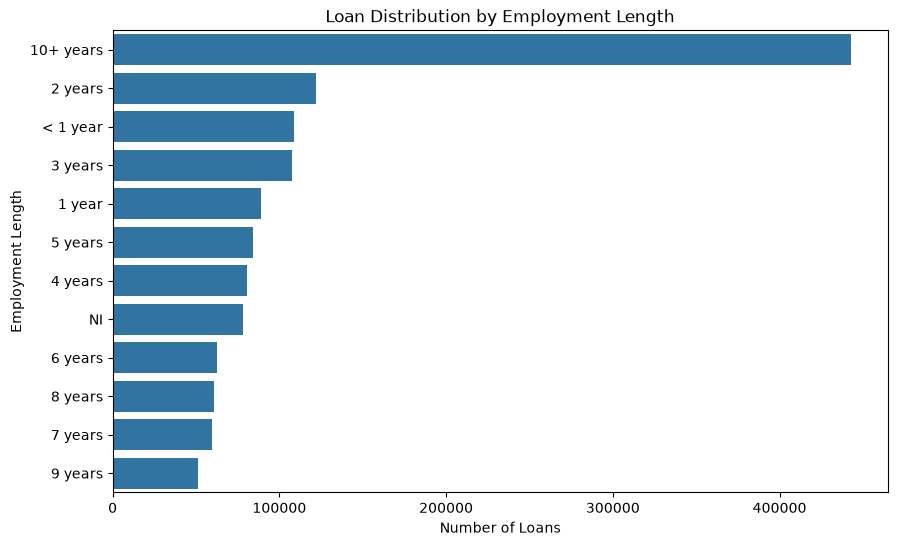

In [13]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    y="emp_length",
    order=df["emp_length"].value_counts().index
)

plt.title("Loan Distribution by Employment Length")
plt.xlabel("Number of Loans")
plt.ylabel("Employment Length")

plt.show()

In [15]:
employment_default =(
    df.groupby('emp_length')['Default'].agg(
        default_count ='sum',
        loan_count = 'count',
        default_rate = 'mean'
    )
    .sort_values('default_rate', ascending = False)
)

employment_default

,default_count,loan_count,default_rate
emp_length,,,
NI,21077,78188,0.269568
1 year,18289,88841,0.205862
< 1 year,22289,108517,0.205396
3 years,21558,107862,0.199866
8 years,12132,60808,0.199513
9 years,10158,51019,0.199102
2 years,24197,122091,0.198188
4 years,15956,80761,0.197571
5 years,16545,84326,0.196203


### Employment Length — EDA Findings

- The NI category has the highest observed default rate at approximately 26.96%, compared with the overall portfolio default rate of 19.98%.
- Borrowers with 10+ years of employment have the lowest observed default rate at approximately 18.80%.
- The 10+ years category represents the largest portfolio segment, with 442,667 loans.
- Borrowers with less than one year and one year of employment show default rates slightly above the portfolio average.
- Default rates do not decrease consistently with every additional year of employment.
- The NI category requires further investigation because its meaning has not yet been established.

These results indicate an association between employment-length categories and observed default behavior. They do not establish causation.

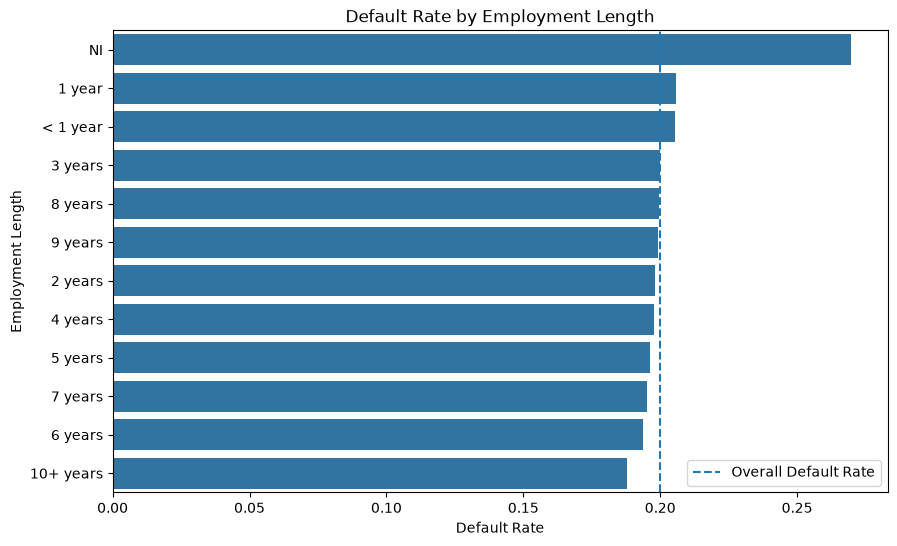

In [16]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=employment_default.reset_index(),
    x='default_rate',
    y='emp_length'
)

plt.axvline(
    df['Default'].mean(),
    linestyle='--',
    label='Overall Default Rate'
)

plt.title("Default Rate by Employment Length")
plt.xlabel("Default Rate")
plt.ylabel("Employment Length")
plt.legend()

plt.show()

### Employment Length — EDA Conclusion

Employment length shows differences in observed loan default rates across borrower categories.

- NI has the highest observed default rate at approximately 26.96%.
- Borrowers with 10+ years of employment have the lowest observed default rate at approximately 18.80%.
- Borrowers with less than one year and one year of employment show default rates above the overall portfolio average.
- Most other employment categories have default rates relatively close to the portfolio average of 19.98%.
- The results suggest an association between employment length and loan default behavior, but do not establish causation.

The NI category requires further investigation because its meaning has not yet been established.

### 6.5.3 Home Ownership Analysis

#### Business Question

Does a borrower's home ownership status have an association with observed loan default behavior?

#### Purpose

Understand the distribution of loans across different home ownership categories and investigate differences in their default rates.

#### Business Importance

Home ownership status provides information about a borrower's residential situation. Comparing default behavior across these categories may help identify patterns in the loan portfolio.

In [19]:
home_ownership_count = df['home_ownership_n'].value_counts()

print('Home Ownership Distribution')
print(home_ownership_count)

Home Ownership Distribution
home_ownership_n
MORTGAGE    666594
RENT        535585
OWN         144985
OTHER          517
Name: count, dtype: int64


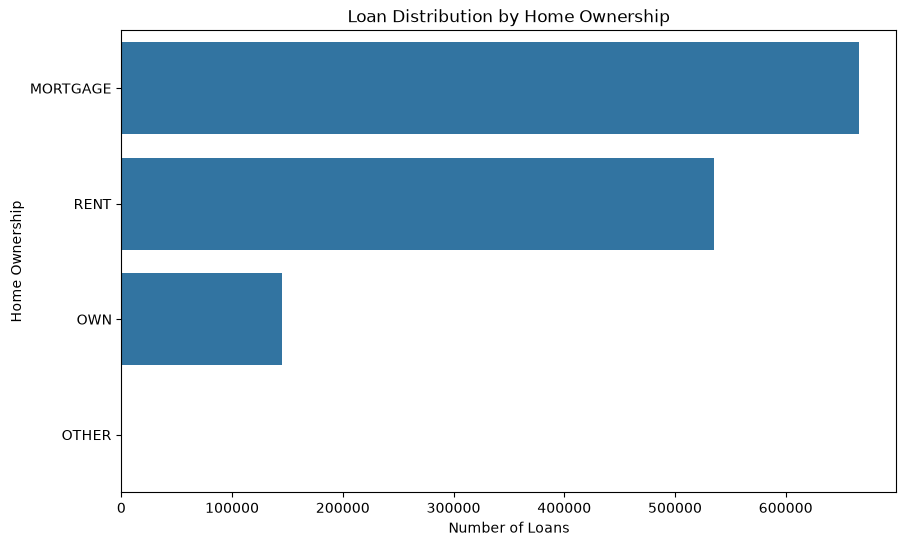

In [20]:
home_ownership_plot = home_ownership_count.reset_index()

home_ownership_plot.columns = ['home_ownership','loan_count']

plt.figure(figsize=(10,6))

sns.barplot(
    data=home_ownership_plot,
    x='loan_count',
    y='home_ownership'
)

plt.title("Loan Distribution by Home Ownership")
plt.xlabel("Number of Loans")
plt.ylabel("Home Ownership")

plt.show()

In [21]:
home_ownership_default = (
    df.groupby("home_ownership_n")["Default"]
    .agg(
        default_count="sum",
        loan_count="count",
        default_rate="mean"
    )
    .sort_values("default_rate", ascending=False)
)

home_ownership_default

,default_count,loan_count,default_rate
home_ownership_n,,,
RENT,124408,535585,0.232284
OWN,29904,144985,0.206256
OTHER,102,517,0.197292
MORTGAGE,114835,666594,0.172271


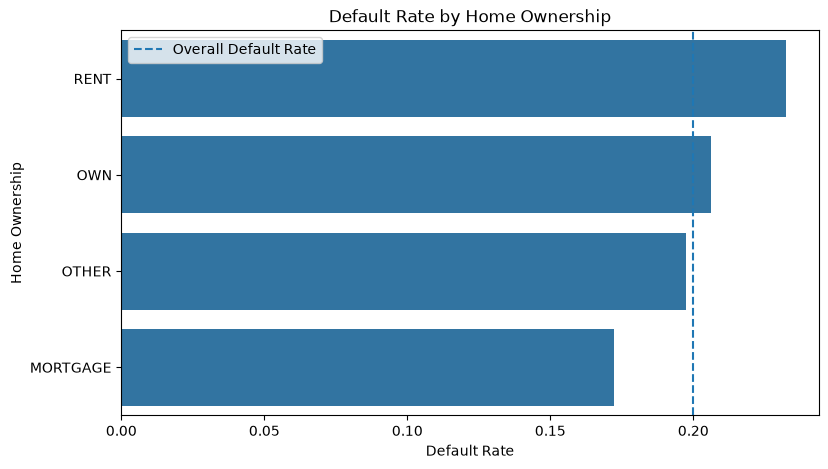

In [22]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=home_ownership_default.reset_index(),
    x="default_rate",
    y="home_ownership_n"
)

plt.axvline(
    df["Default"].mean(),
    linestyle="--",
    label="Overall Default Rate"
)

plt.title("Default Rate by Home Ownership")
plt.xlabel("Default Rate")
plt.ylabel("Home Ownership")
plt.legend()

plt.show()

### Home Ownership — EDA Findings

- RENT has the highest observed default rate at approximately 23.23%, above the overall portfolio default rate of 19.98%.
- MORTGAGE has a comparatively lower default rate of approximately 17.23%.
- OWN shows a default rate of approximately 20.63%, slightly above the portfolio average.
- OTHER has a default rate of approximately 19.73%, but represents only 517 loans. Its result should be interpreted cautiously.
- The results indicate an association between home ownership status and observed loan default behavior.

These findings do not establish causation. Other borrower characteristics may influence the observed differences.

### 6.5.4 State Analysis

#### Business Question

Does borrower location, represented by state, have an association with observed loan default behavior?

#### Purpose

Understand the geographical distribution of loans across US states and investigate differences in observed default rates.

#### Business Importance

Geographical analysis can help identify regional variations in the loan portfolio and highlight states that may require further credit-risk investigation.

In [23]:
state_counts = df["addr_state"].value_counts()

print("Loan Distribution by State")
print(state_counts)

Loan Distribution by State
addr_state
CA    196805
TX    110307
NY    110075
FL     95815
IL     51858
NJ     48576
PA     45640
OH     43935
GA     43470
VA     38107
NC     37812
MI     35302
AZ     32733
MD     31295
MA     31066
CO     29722
WA     29218
MN     24001
IN     21720
MO     21328
TN     20393
NV     20282
CT     19787
WI     17782
AL     16640
OR     16415
SC     16004
LA     15520
KY     12868
OK     12291
KS     11262
AR     10058
UT     10045
NM      7374
HI      6763
MS      6593
NH      6463
RI      5879
WV      4888
MT      3831
DE      3804
NE      3591
DC      3485
AK      3194
WY      2926
SD      2770
VT      2655
ME      2029
ID      1689
ND      1601
IA        14
Name: count, dtype: int64


In [24]:
state_default = (
    df.groupby("addr_state")["Default"]
    .agg(
        default_count="sum",
        loan_count="count",
        default_rate="mean"
    )
    .sort_values("default_rate", ascending=False)
)

state_default

,default_count,loan_count,default_rate
addr_state,,,
MS,1722,6593,0.261186
NE,905,3591,0.252019
AR,2425,10058,0.241102
AL,3933,16640,0.236358
OK,2884,12291,0.234643
LA,3596,15520,0.231701
NY,24267,110075,0.220459
NV,4457,20282,0.219752
FL,20599,95815,0.214987


In [25]:
state_filtered = state_default[
    state_default["loan_count"] >= 1000
].copy()

state_filtered = state_filtered.sort_values(
    "default_rate",
    ascending=False
)

state_filtered.head(15)

,default_count,loan_count,default_rate
addr_state,,,
MS,1722,6593,0.261186
NE,905,3591,0.252019
AR,2425,10058,0.241102
AL,3933,16640,0.236358
OK,2884,12291,0.234643
LA,3596,15520,0.231701
NY,24267,110075,0.220459
NV,4457,20282,0.219752
FL,20599,95815,0.214987


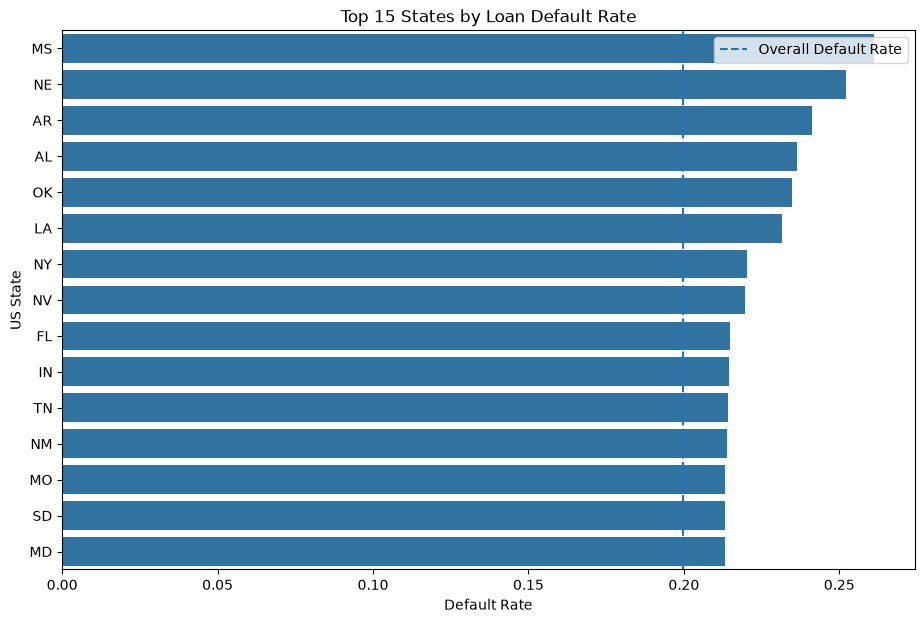

In [26]:
plt.figure(figsize=(11, 7))

sns.barplot(
    data=state_filtered.head(15).reset_index(),
    x="default_rate",
    y="addr_state"
)

plt.axvline(
    df["Default"].mean(),
    linestyle="--",
    label="Overall Default Rate"
)

plt.title("Top 15 States by Loan Default Rate")
plt.xlabel("Default Rate")
plt.ylabel("US State")
plt.legend()

plt.show()

### State-Level EDA Findings

- Mississippi has the highest observed default rate among the selected states, at approximately 26.12%.
- Nebraska, Arkansas, Alabama, and Oklahoma also show elevated default rates.
- New York has a substantial portfolio volume of 110,075 loans and an observed default rate of approximately 22.05%.
- Florida has 95,815 loans and an observed default rate of approximately 21.50%.
- All 15 selected states have default rates above the overall portfolio default rate of 19.98%.
- States with fewer than 1,000 loans were excluded from this comparison to reduce the influence of very small samples.

These findings indicate geographical variation in observed loan default behavior. They do not establish causation. Further statistical investigation is required to assess whether these differences are meaningful.

## 6.6 Target-Based Numerical Feature Analysis

### Business Question

How do borrower financial characteristics differ between fully paid loans and defaulted loans?

### Numerical Features

- revenue
- dti_n
- loan_amnt
- fico_n

### Purpose

Compare numerical borrower characteristics across the two target classes to identify potential differences in financial profiles.

### Business Importance

Understanding how borrower income, indebtedness, requested loan amounts, and credit scores differ between defaulted and fully paid loans can help identify potential credit-risk indicators.

In [27]:
target_numeric_summary = (
    df.groupby("Default")[
        ["revenue", "dti_n", "loan_amnt", "fico_n"]
    ]
    .agg(["mean", "median"])
    .T
)

target_numeric_summary

Default                      0             1
revenue   mean    78785.658732  71698.229044
          median  66000.000000  60000.000000
dti_n     mean       17.798860     20.164279
          median     17.120000     19.790000
loan_amnt mean    14123.911174  15547.024130
          median  12000.000000  14300.000000
fico_n    mean      700.239519    689.825440
          median    692.000000    682.000000

### Numerical Features vs Default — EDA Findings

- Borrowers with fully paid loans have higher mean and median self-declared annual income than borrowers with defaulted loans.
- Defaulted borrowers show higher mean and median DTI values, suggesting a greater observed debt burden.
- Defaulted borrowers have higher average and median loan amounts.
- Fully paid borrowers have higher mean and median FICO scores than defaulted borrowers.
- These differences suggest that income, DTI, loan amount, and FICO score may contain useful information for credit-risk analysis.

These findings describe associations with observed default status. They do not establish causation or statistical significance.

In [28]:
eda_sample = (
    df.groupby("Default", group_keys=False)
    .sample(n=20000, random_state=42)
)

print(eda_sample["Default"].value_counts())

Default
0    20000
1    20000
Name: count, dtype: int64


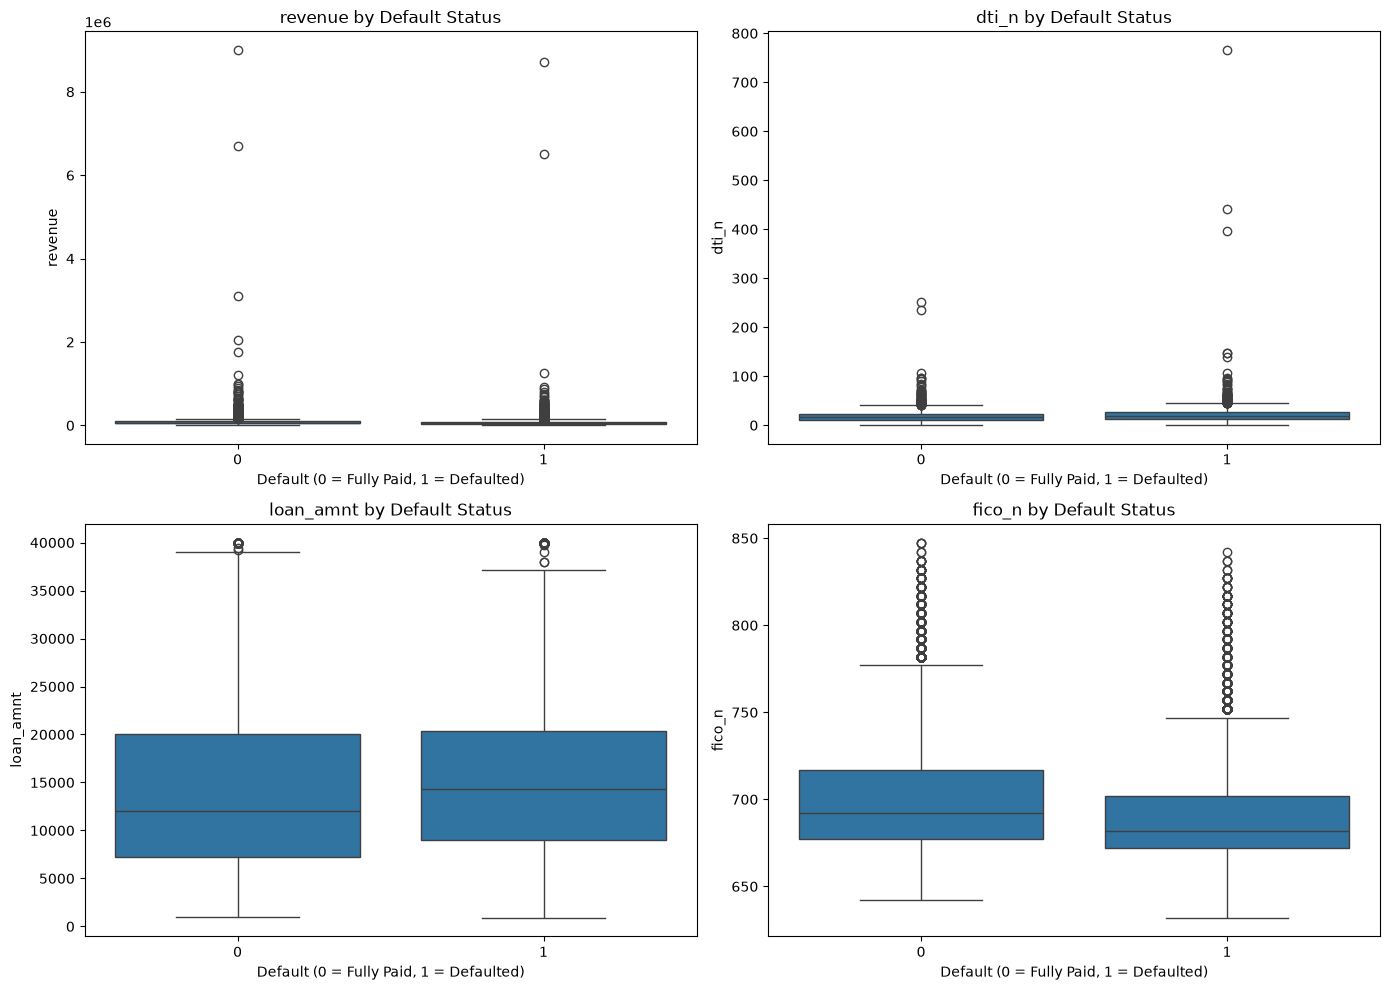

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

features = ["revenue", "dti_n", "loan_amnt", "fico_n"]

for feature, ax in zip(features, axes.flatten()):
    sns.boxplot(
        data=eda_sample,
        x="Default",
        y=feature,
        ax=ax
    )

    ax.set_title(f"{feature} by Default Status")
    ax.set_xlabel("Default (0 = Fully Paid, 1 = Defaulted)")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()

### Boxplot Analysis — Key Findings

- Fully paid borrowers show a higher median self-declared annual income than defaulted borrowers.
- Defaulted borrowers show a higher median DTI, indicating a greater observed debt burden.
- Defaulted borrowers have a higher median loan amount.
- Fully paid borrowers have higher median FICO scores than defaulted borrowers.
- All four features show some overlap between target classes, meaning no single feature completely separates defaulted and fully paid borrowers.
- Extreme observations are visible in income and DTI distributions.

These visual patterns support the earlier numerical comparisons. They represent associations, not causal relationships.

In [30]:
correlation_features = [
    "revenue",
    "dti_n",
    "loan_amnt",
    "fico_n",
    "experience_c",
    "Default"
]

correlation_matrix = df[correlation_features].corr()

correlation_matrix

,revenue,dti_n,loan_amnt,fico_n,experience_c,Default
revenue,1.000000,-0.125336,0.321970,0.075880,0.000377,-0.040275
dti_n,-0.125336,1.000000,0.035771,-0.068288,0.004178,0.095905
loan_amnt,0.321970,0.035771,1.000000,0.101474,0.005381,0.065289
fico_n,0.075880,-0.068288,0.101474,1.000000,-0.002467,-0.130742
experience_c,0.000377,0.004178,0.005381,-0.002467,1.000000,0.000859
Default,-0.040275,0.095905,0.065289,-0.130742,0.000859,1.000000


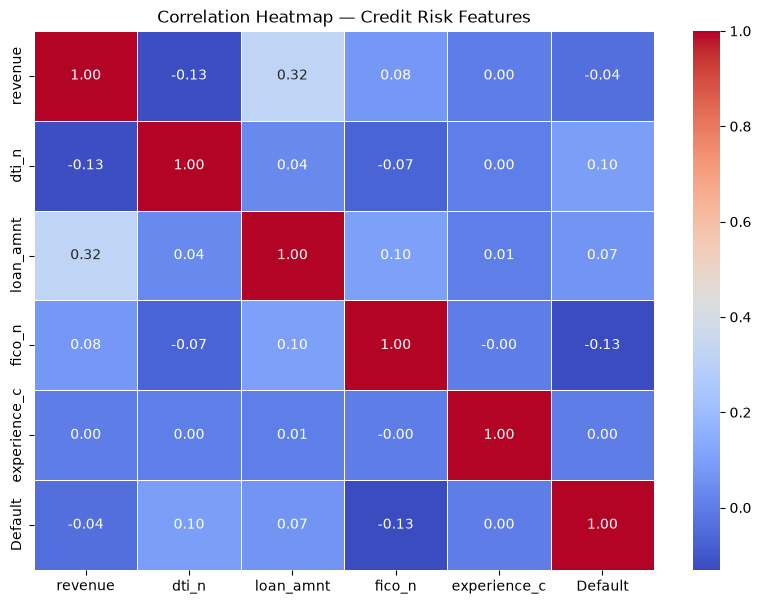

In [31]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap — Credit Risk Features")
plt.show()

### Correlation Analysis — Key Findings

- FICO score has the strongest absolute correlation with loan default (-0.13), indicating a negative association.
- DTI shows a weak positive correlation with default (0.10).
- Loan amount has a weak positive correlation with default (0.07).
- Borrower annual income has a very weak negative correlation with default (-0.04).
- Experience has almost zero linear correlation with the target.
- Revenue and loan amount show the strongest predictor-to-predictor correlation (0.32).
- No strong pairwise correlation was observed among the numerical predictors.

The correlation analysis does not indicate severe pairwise multicollinearity. Further verification using Variance Inflation Factor (VIF) will be considered during feature analysis.

Correlation measures linear association and does not establish causation.

## 6.8 Outlier Analysis

### Business Question

Are there extreme financial observations in the dataset, and how should they be handled?

### Purpose

Identify potential outliers in borrower income, indebtedness ratio, and requested loan amount using the Interquartile Range (IQR) method.

### Business Importance

Extreme financial observations can influence statistical summaries, visualizations, and machine learning models. Identifying them helps us distinguish potentially unusual but valid financial records from data-quality problems.

In [32]:
outlier_features = ["revenue", "dti_n", "loan_amnt"]

outlier_summary = {}

for feature in outlier_features:
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    ]

    outlier_summary[feature] = {
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": len(outliers),
        "outlier_percentage": round(
            len(outliers) / len(df) * 100, 2
        )
    }

outlier_summary

{'revenue': {'lower_bound': np.float64(-21500.0),
  'upper_bound': np.float64(160100.0),
  'outlier_count': 62998,
  'outlier_percentage': 4.67},
 'dti_n': {'lower_bound': np.float64(-6.555),
  'upper_bound': np.float64(42.445),
  'outlier_count': 5468,
  'outlier_percentage': 0.41},
 'loan_amnt': {'lower_bound': np.float64(-10062.5),
  'upper_bound': np.float64(38037.5),
  'outlier_count': 7131,
  'outlier_percentage': 0.53}}

### Outlier Analysis — Key Findings

- Revenue contains 62,998 IQR outliers (4.67%), representing unusually high borrower-reported annual income.
- DTI contains 5,468 IQR outliers (0.41%), indicating unusually high indebtedness ratios.
- Loan amount contains 7,131 IQR outliers (0.53%), representing unusually large loan requests.
- Statistical outliers are not necessarily invalid observations.
- Valid financial outliers were retained during the data-quality phase to preserve potentially meaningful borrower information.

Further investigation and appropriate scaling or transformation may be considered during feature engineering and model development.

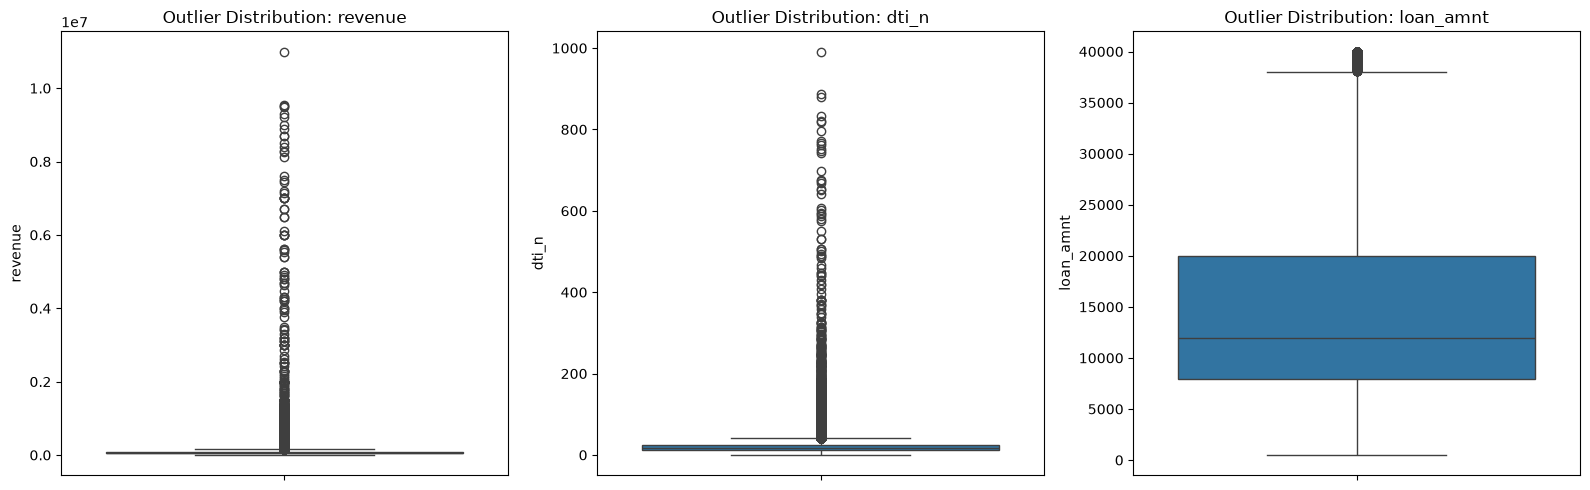

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

outlier_features = ["revenue", "dti_n", "loan_amnt"]

for feature, ax in zip(outlier_features, axes):

    sns.boxplot(
        y=df[feature],
        ax=ax
    )

    ax.set_title(f"Outlier Distribution: {feature}")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()

### Outlier Visualization — Key Findings

- Revenue shows a strongly right-skewed distribution with numerous high-income observations.
- DTI also shows a strongly right-skewed distribution with several extreme values.
- Loan amount has a comparatively concentrated distribution, with a smaller number of high-value observations.
- Revenue and DTI have more visibly extended upper tails than loan amount.
- These observations are potential statistical outliers and were retained during data-quality processing because extreme values are not necessarily data errors.

No observations were removed or modified during this analysis.

## 6.9 Target-Based Categorical Analysis

### Business Question

Do loan default rates differ across borrower and loan categories?

### Purpose

Compare default rates across loan purpose, employment length, and home ownership categories.

### Business Importance

Identifying categories with higher observed default rates can help lenders understand portfolio risk and investigate potentially vulnerable borrower segments.

In [34]:
purpose_default = (
    df.groupby("purpose")["Default"]
    .agg(
        default_count="sum",
        loan_count="count",
        default_rate="mean"
    )
    .sort_values("default_rate", ascending=False)
)

purpose_default

,default_count,loan_count,default_rate
purpose,,,
small_business,4650,15575,0.298555
renewable_energy,222,936,0.237179
moving,2229,9520,0.234139
house,1598,7294,0.219084
medical,3409,15606,0.218442
debt_consolidation,165258,781206,0.211542
other,16501,78263,0.210840
educational,88,423,0.208038
vacation,1743,9083,0.191897


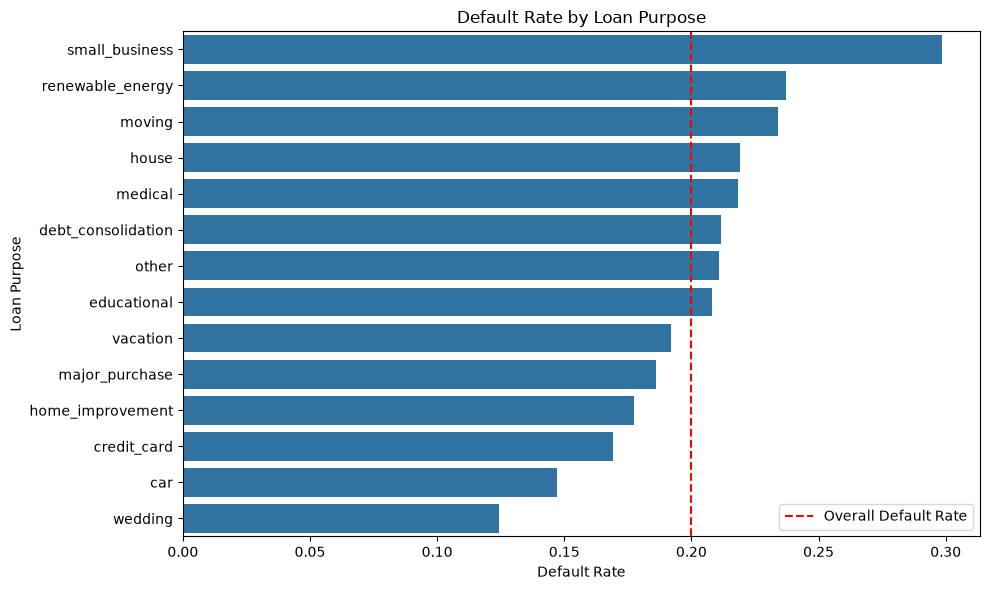

In [35]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=purpose_default.reset_index(),
    x="default_rate",
    y="purpose"
)

plt.axvline(
    df["Default"].mean(),
    color="red",
    linestyle="--",
    label="Overall Default Rate"
)

plt.title("Default Rate by Loan Purpose")
plt.xlabel("Default Rate")
plt.ylabel("Loan Purpose")
plt.legend()
plt.tight_layout()
plt.show()

### Loan Purpose — EDA Findings

- Small-business loans have the highest observed default rate at approximately 29.86%.
- Renewable-energy and moving loans also show default rates above the overall portfolio average.
- Debt consolidation represents the largest loan-purpose category, with 781,206 loans, and has a default rate of approximately 21.15%.
- Credit-card, car, and wedding loans have default rates below the overall portfolio average.
- Categories with smaller loan counts should be interpreted cautiously.

These findings indicate that loan purpose may provide useful information for credit-risk analysis. However, these relationships do not establish causation.

## 6.X EDA Summary and Key Findings

### 1. Portfolio Overview
- The dataset contains approximately 1.35 million loan records.
- The overall default rate is 19.98%.
- The target variable is moderately imbalanced.

### 2. Numerical Feature Findings
- Borrower self-declared annual income and DTI are right-skewed.
- Defaulted borrowers show higher average DTI and loan amounts.
- Fully paid borrowers show higher average FICO scores.

### 3. Categorical Feature Findings
- Small-business loans have the highest observed default rate among loan purposes.
- Borrowers with unknown employment length (NI) show a higher default rate.
- Renters show a higher default rate than homeowners with a mortgage.
- Some US states have default rates above the overall portfolio average.

### 4. Correlation Findings
- FICO score has a negative correlation with default status.
- DTI and loan amount have positive correlations with default status.
- No strong linear correlation was observed among the selected numerical features.

### 5. Analytical Conclusion
The EDA identified several numerical and categorical variables that may contain useful information for predicting loan default.

These are exploratory findings. Further statistical analysis and hypothesis testing are required before drawing stronger conclusions.